In [1]:
import torch

device = "mps" if torch.backends.mps.is_available() else "cpu"

print("Using device:", device)


Using device: mps


In [2]:

from time import perf_counter
import numpy as np
import pandas as pd
import torch
from transformers import BertTokenizer, BertModel

# get Trainning set
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
train_texts = train_df["text"].to_list()
test_texts = test_df["text"].to_list()
y_train = train_df["label"]
y_test = test_df["label"]

### BERT Embeddings ###
# Load BERT model and tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased").to(device).eval()

# Function to get BERT embeddings
def get_bert_embedding(texts):
    inputs = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:, 0, :].squeeze().cpu().numpy()  # CLS token representation



def embed_all(texts, batch_size=64):
    batch_embeddings = []                             
    for start in range(0, len(texts), batch_size):    
        batch = texts[start : start + batch_size]     
        batch_embeddings.append(get_bert_embedding(batch))  
    return np.vstack(batch_embeddings)                


start = perf_counter()
train_embeddings = embed_all(train_texts)
test_embeddings = embed_all(test_texts)
print(f"Embedding time: {perf_counter() - start:.1f} seconds")


print("Train embeddings:", train_embeddings.shape)   
print("Test embeddings:", test_embeddings.shape)     
print("Any NaN?", np.isnan(train_embeddings).any())  

for i in range(3):
    print(f"\nMessage {i+1}: {train_texts[i]}")
    print(f"First 5 dims: {train_embeddings[i][:5]}")

W1113 12:14:55.988000 2118 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding time: 44.9 seconds
Train embeddings: (4457, 768)
Test embeddings: (1115, 768)
Any NaN? False

Message 1: Going on nothing great.bye
First 5 dims: [ 0.1260943   0.03758216  0.27378958 -0.40432614 -0.21899179]

Message 2: I wont. So wat's wit the guys
First 5 dims: [ 0.02899013  0.22356406 -0.05413764  0.02877156 -0.54603297]

Message 3: Ok k..sry i knw 2 siva..tats y i askd..
First 5 dims: [-0.23296912  0.42630613  0.2641206  -0.18314976 -0.25548822]


## Tune KNN

We use the BERT [CLS] embeddings with cosine distance. BERT is pretrained and frozen, so it learns nothing from our data. That makes it safe to compute the embeddings once, before cross-validation, with no leakage between folds. We test the same `k` values as Part A, {1, 3, 5, 7, 11, 21}, using the same five stratified folds. We select `k` by mean spam F1 because spam is only about 13% of messages, so accuracy alone can look high even for a weak model.

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# No Pipeline needed: the embeddings are already computed and BERT does not learn from the data
part_c_knn = KNeighborsClassifier(metric="cosine", algorithm="brute")

# Same folds and k values as Part A, so the two parts are compared fairly
part_c_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
part_c_search = GridSearchCV(
    part_c_knn,
    {"n_neighbors": [1, 3, 5, 7, 11, 21]},
    cv=part_c_cv,
    scoring={"accuracy": "accuracy", "f1": "f1"},  # score both metrics in each fold
    refit="f1",                                    # pick the best k by spam F1
)

start = perf_counter()
part_c_search.fit(train_embeddings, y_train)
part_c_fit_seconds = perf_counter() - start

part_c_cv_results = pd.DataFrame({
    "k": part_c_search.cv_results_["param_n_neighbors"],
    "Mean CV accuracy": part_c_search.cv_results_["mean_test_accuracy"],
    "Mean CV spam F1": part_c_search.cv_results_["mean_test_f1"],
})
print(part_c_cv_results.to_string(index=False, float_format="{:.4f}".format))
print(f"\nBest k (by spam F1): {part_c_search.best_params_['n_neighbors']}")

 k  Mean CV accuracy  Mean CV spam F1
 1            0.9827           0.9372
 3            0.9829           0.9374
 5            0.9836           0.9398
 7            0.9829           0.9375
11            0.9827           0.9367
21            0.9829           0.9377

Best k (by spam F1): 5


## Test results

`GridSearchCV` refits KNN on the full training set with the best `k`. Precision, recall, and F1 refer to the spam class.

Representation             BERT [CLS] embeddings
Dimensions                                   768
Best k                                         5
Test accuracy                             0.9821
Spam precision                            0.9216
Spam recall                               0.9463
Spam F1                                   0.9338
CV + fit (seconds)                        1.7093
Test prediction (seconds)                 0.0949


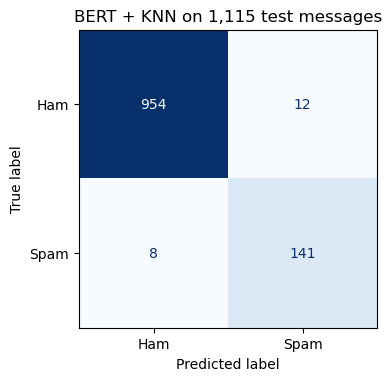

In [4]:
start = perf_counter()
part_c_pred = part_c_search.predict(test_embeddings)
part_c_predict_seconds = perf_counter() - start

part_c_precision, part_c_recall, part_c_f1, _ = precision_recall_fscore_support(
    y_test, part_c_pred, average="binary", pos_label=1, zero_division=0,
)
part_c_matrix = confusion_matrix(y_test, part_c_pred, labels=[0, 1])
part_c_results = pd.DataFrame([{
    "Representation": "BERT [CLS] embeddings",
    "Dimensions": train_embeddings.shape[1],
    "Best k": part_c_search.best_params_["n_neighbors"],
    "Test accuracy": accuracy_score(y_test, part_c_pred),
    "Spam precision": part_c_precision,
    "Spam recall": part_c_recall,
    "Spam F1": part_c_f1,
    "CV + fit (seconds)": part_c_fit_seconds,
    "Test prediction (seconds)": part_c_predict_seconds,
}])
print(part_c_results.T.to_string(header=False, float_format="{:.4f}".format))

fig, ax = plt.subplots(figsize=(4.8, 3.7), layout="constrained")
ConfusionMatrixDisplay(part_c_matrix, display_labels=["Ham", "Spam"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_title(f"BERT + KNN on {len(y_test):,} test messages")
plt.show()

In [5]:
# Create a table with actual and predicted labels
error_df = test_df[["text", "label"]].copy()
error_df["predicted_label"] = part_c_pred

# Identify false positives (ham predicted as spam)
false_positives = error_df[
    (error_df["label"] == 0) &
    (error_df["predicted_label"] == 1)
]

# Identify false negatives (spam predicted as ham)
false_negatives = error_df[
    (error_df["label"] == 1) &
    (error_df["predicted_label"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

False positives: 12
False negatives: 8


In [6]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

print("FALSE POSITIVES")
display(false_positives)

print("FALSE NEGATIVES")
display(false_negatives)

FALSE POSITIVES


,text,label,predicted_label
42,V nice! Off 2 sheffield tom 2 air my opinions on categories 2 b used 2 measure ethnicity in next census. Busy transcribing. :-),0,1
79,Msgs r not time pass.They silently say that I am thinking of U right now and also making U think of me at least 4 a moment. Gd nt.swt drms @Shesil,0,1
323,HCL chennai requires FRESHERS for voice process.Excellent english needed.Salary upto &lt;#&gt; .Call Ms.Suman &lt;#&gt; for Telephonic interview -via Indyarocks.com,0,1
444,", , and picking them up from various points | going 2 yeovil | and they will do the motor project 4 3 hours | and then u take them home. || 12 2 5.30 max. || Very easy",0,1
450,Unlimited texts. Limited minutes.,0,1
529,"Camera quite good, 10.1mega pixels, 3optical and 5digital dooms. Have a lovely holiday, be safe and i hope you hav a good journey! Happy new year to you both! See you in a couple of weeks!",0,1
546,Today is ACCEPT DAY..U Accept me as? Brother Sister Lover Dear1 Best1 Clos1 Lvblefrnd Jstfrnd Cutefrnd Lifpartnr Belovd Swtheart Bstfrnd No rply means enemy,0,1
820,Ujhhhhhhh computer shipped out with address to sandiago and parantella lane. Wtf. Poop.,0,1
871,Apps class varaya elaya.,0,1
951,Let Ur Heart Be Ur Compass Ur Mind Ur Map Ur Soul Ur Guide And U Will Never loose in world....gnun - Sent via WAY2SMS.COM,0,1


FALSE NEGATIVES


,text,label,predicted_label
196,ringtoneking 84484,1,0
235,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0
357,Bought one ringtone and now getting texts costing 3 pound offering more tones etc,1,0
433,"Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 08712400603",1,0
841,ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are bringing in a real breath of sunshine.,1,0
852,"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",1,0
946,Adult 18 Content Your video will be with you shortly,1,0
1035,RCT' THNQ Adrian for U text. Rgds Vatian,1,0


In [7]:
false_positives.to_csv("BERT_False_Positives.csv", index=False)
false_negatives.to_csv("BERT_False_Negatives.csv", index=False)